# Training models for subjective cognitive decline

**DSC5001 · Part C · BRFSS 2023**

We fit logistic regression, random forest and XGBoost to predict self-reported subjective cognitive decline (SCD). Each model uses the same respondents twice. The base set has 14 predictors. The full set adds 11 items on adverse childhood experiences (ACEs). We use Member B's split, feature groups and F1 tuning rule.

In [1]:
from ast import literal_eval
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import clear_output, display
from joblib import cpu_count
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

SEED = 42
THREADS = min(cpu_count(), 4)

## Upload the data

Choose one CSV at each prompt, in this order. The first file comes from data preparation. The other two come from Section B.

1. `BRFSS_2023_ML_Feature_Dataset.csv`
2. `B_split_assignments.csv`
3. `B_best_params.csv`

In [2]:
def upload_csv(project_path):
    clear_output(wait=True)
    print(f"Choose {project_path}", flush=True)
    with TemporaryDirectory() as folder:
        local_path = Path(folder) / Path(project_path).name
        files.upload_file(str(local_path))
        return pd.read_csv(local_path, encoding="utf-8-sig")


# Choose BRFSS_2023_ML_Feature_Dataset.csv for the survey data and SCD label.
data = upload_csv("BRFSS_2023_ML_Feature_Dataset.csv")

# Choose B_split_assignments.csv to keep B's training and test groups.
b_split = upload_csv("B_split_assignments.csv").set_index("row_index")

# Choose B_best_params.csv for the model settings B selected.
b_results = upload_csv("B_best_params.csv").set_index("Model")

# Verify the row assignments once, before selecting the training rows.
split = b_split["Dataset_Split"].sort_index()
if not split.equals(data["Dataset_Split"]):
    raise ValueError("The row assignments in the preparation file and B's file do not match.")
train_ids = split.index[split.eq("train")]
test_ids = split.index[split.eq("test")]
y_train = data.loc[train_ids, "SCD"].astype(int)
clear_output()
print(f"Training: {len(train_ids):,} respondents, {y_train.sum():,} with SCD ({y_train.mean():.1%}). "
      f"Test: {len(test_ids):,} respondents.")

Training: 28,603 respondents, 4,890 with SCD (17.1%). Test: 7,151 respondents.


## Prepare the predictors

We follow B's column groups. In each training fold, the pipeline fills age with the median and scales it. It fills other missing values with the most common value and one-hot encodes the categories. The validation rows use the rules learned from that fold's training rows.

In [3]:
age = ["_AGE80"]
categories = ["_RACEGR3", "_STATE", "EDUCA", "INCOME3", "MARITAL", "_BMI5CAT", "DIABETE4", "_SMOKER3"]
base_binary = ["SEXVAR", "Depression_bin", "Stroke_bin", "HighBP_bin", "PhysicalActivity_bin"]
ace = ["ACEDEPRS_bin", "ACEDRINK_bin", "ACEDRUGS_bin", "ACEPRISN_bin", "ACEDIVRC_bin",
       "ACEPUNCH_bin", "ACEHURT1_bin", "ACESWEAR_bin", "ACETOUCH_bin", "ACETTHEM_bin", "ACEHVSEX_bin"]
binary_sets = {"Base": base_binary, "Base + ACE": base_binary + ace}
feature_sets = {name: binary + age + categories for name, binary in binary_sets.items()}
X_train = data.loc[train_ids, feature_sets["Base + ACE"]]


def make_preprocessor(binary, sparse_categories):
    return ColumnTransformer([
        ("bin", SimpleImputer(strategy="most_frequent"), binary),
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), age),
        ("cat", Pipeline([
            ("fill", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=sparse_categories)),
        ]), categories),
    ])

## Set the folds and search ranges

Each model uses the same five stratified folds and a seed of 42. We select settings by the mean F1 score for the SCD class. We use the models' standard 0.5 cutoff. Logistic regression and random forest give more weight to the smaller class. For XGBoost, the search tries three weights for an SCD case.

For the full logistic regression and random forest, we read B's winning settings and run those settings again on the five folds. For their base versions, we use B's original search ranges. We tune XGBoost separately for each feature set.

In [4]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
models = {
    "Logistic Regression": LogisticRegression(solver="lbfgs", class_weight="balanced",
                                              max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=THREADS),
    "XGBoost": XGBClassifier(n_estimators=160, objective="binary:logistic", tree_method="hist",
                             eval_metric="logloss", random_state=SEED, n_jobs=THREADS),
}
grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 10, 20],
                      "clf__min_samples_split": [2, 10]},
    "XGBoost": {"clf__max_depth": [2, 4], "clf__learning_rate": [0.04, 0.10],
                "clf__scale_pos_weight": [1, 3, 5]},
}
# The default L2 penalty with lbfgs matches B's logistic regression.
b_grids = {
    name: {key: [value] for key, value in literal_eval(params).items() if key != "clf__penalty"}
    for name, params in b_results["Best_Params"].items()
}
metrics = {"F1": "f1", "Precision": "precision", "Recall": "recall", "ROC-AUC": "roc_auc"}

## Fit the six pipelines

Each fit starts with the original survey columns. XGBoost gets a dense matrix so a zero stays a zero. At the end of each search, the selected pipeline is fitted on all training rows. This is the longest cell.

In [6]:
from time import perf_counter

fitted_models, rows, fold_rows = {}, [], []
pipeline_count = len(models) * len(feature_sets)
with threadpool_limits(limits=THREADS):
    for name, estimator in models.items():
        for inputs, columns in feature_sets.items():
            grid = grids[name]
            if inputs == "Base + ACE" and name in b_grids:
                grid = b_grids[name]
            pipeline = Pipeline([
                ("prep", make_preprocessor(binary_sets[inputs], sparse_categories=name != "XGBoost")),
                ("clf", estimator),
            ])
            stage = f"[{len(fitted_models) + 1}/{pipeline_count}] {name} | {inputs}"
            print(f"\n{stage} | Starting cross-validation", flush=True)
            started = perf_counter()
            # Show the fold, settings, scores and time after each validation fit.
            search = GridSearchCV(pipeline, grid, scoring=metrics, refit="F1", cv=folds,
                                  n_jobs=1, error_score="raise", verbose=3)
            search.fit(X_train[columns], y_train)
            print(f"{stage} | Final fit complete | Best mean F1 {search.best_score_:.4f} "
                  f"| {perf_counter() - started:.1f} s", flush=True)
            fitted_models[name, inputs] = search.best_estimator_
            chosen, cv = search.best_index_, search.cv_results_
            fold_f1 = [cv[f"split{i}_test_F1"][chosen] for i in range(len(folds))]
            selected = {key.removeprefix("clf__"): value for key, value in search.best_params_.items()}
            rows.append({
                "Model": name, "Features": inputs,
                **{metric: cv[f"mean_test_{metric}"][chosen] for metric in metrics},
                "F1 SD": np.std(fold_f1, ddof=1),
                "Selected settings": ", ".join(f"{key}={value}" for key, value in selected.items()),
            })
            for fold, value in enumerate(fold_f1, start=1):
                fold_rows.append((name, inputs, fold, value))
results = pd.DataFrame(rows)[["Model", "Features", "F1", "F1 SD", "Precision", "Recall",
                              "ROC-AUC", "Selected settings"]]
fold_scores = pd.DataFrame(fold_rows, columns=["Model", "Features", "Fold", "F1"])


[1/6] Logistic Regression | Base | Starting cross-validation
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV 1/5] END clf__C=0.01; F1: (test=0.381) Precision: (test=0.290) ROC-AUC: (test=0.698) Recall: (test=0.553) total time=   0.2s
[CV 2/5] END clf__C=0.01; F1: (test=0.374) Precision: (test=0.286) ROC-AUC: (test=0.690) Recall: (test=0.541) total time=   0.2s
[CV 3/5] END clf__C=0.01; F1: (test=0.391) Precision: (test=0.297) ROC-AUC: (test=0.697) Recall: (test=0.573) total time=   0.2s
[CV 4/5] END clf__C=0.01; F1: (test=0.371) Precision: (test=0.287) ROC-AUC: (test=0.685) Recall: (test=0.527) total time=   0.2s
[CV 5/5] END clf__C=0.01; F1: (test=0.402) Precision: (test=0.310) ROC-AUC: (test=0.699) Recall: (test=0.570) total time=   0.2s
[CV 1/5] END clf__C=0.1; F1: (test=0.381) Precision: (test=0.291) ROC-AUC: (test=0.699) Recall: (test=0.552) total time=   0.2s
[CV 2/5] END clf__C=0.1; F1: (test=0.378) Precision: (test=0.290) ROC-AUC: (test=0.690) Recall: (test=0.5

## What changes when we add ACE?

**Figure 1.** Each bar shows the gain in mean F1 after adding the 11 ACE items. F1 combines precision and recall for the SCD class. We use the same five validation folds and calculate the gains before rounding the scores.

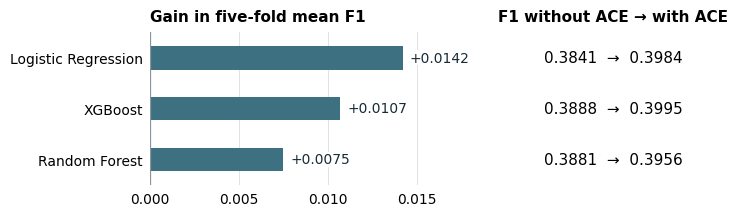

In [7]:
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans", "Arial"]})
f1 = fold_scores.pivot_table(index="Model", columns="Features", values="F1", aggfunc="mean")
f1_gain = (f1["Base + ACE"] - f1["Base"]).sort_values(ascending=False)


def draw_bars(ax, values, labels, color):
    positions = np.arange(len(values))
    bars = ax.barh(positions, values, height=0.46, color=color)
    ax.bar_label(bars, labels=labels, padding=5, fontsize=10, color="#182b35",
                 bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.4})
    ax.set_yticks(positions, values.index)
    ax.set_ylim(len(values) - 0.5, -0.5)
    ax.spines[:].set_visible(False)
    ax.axvline(0, color="#86969c", lw=0.9)
    ax.grid(axis="x", color="#dce3e6", lw=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=5, labelsize=10)


gain_fig, (gain_ax, score_ax) = plt.subplots(
    1, 2, figsize=(7.25, 2.05), width_ratios=[1.5, 1], sharey=True, layout="constrained"
)
draw_bars(gain_ax, f1_gain, [f"{v:+.4f}" for v in f1_gain], "#3d7181")
gain_ax.set_title("Gain in five-fold mean F1", loc="left", fontsize=11, weight="bold", pad=8)
gain_ax.margins(x=0.35)
gain_ax.xaxis.set_major_locator(plt.MultipleLocator(0.005))
gain_ax.xaxis.set_major_formatter("{x:.3f}")

score_ax.set_title("F1 without ACE → with ACE", fontsize=11, weight="bold", pad=8)
score_ax.set_axis_off()
for row, name in enumerate(f1_gain.index):
    before, after = f1.loc[name, ["Base", "Base + ACE"]]
    score_ax.text(0.5, row, f"{before:.4f}  →  {after:.4f}", ha="center", va="center", fontsize=11)
plt.show()

## How well do the models find people with SCD?

**Figure 2.** All three models use ACE and the same cutoff of 0.5. Precision starts with everyone the model flagged. Recall starts with everyone who reported SCD. The labels show the mean rate across the five validation folds.

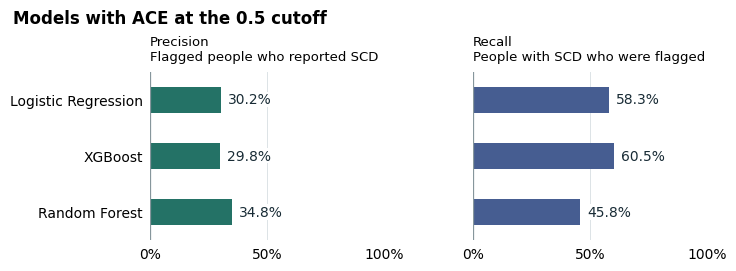

In [8]:
full = results.loc[results["Features"].eq("Base + ACE")].set_index("Model").loc[f1_gain.index]
rate_fig, rate_axes = plt.subplots(1, 2, figsize=(7.25, 2.6), sharey=True,
                                  gridspec_kw={"wspace": 0.16}, layout="constrained")
rate_fig.suptitle("Models with ACE at the 0.5 cutoff", x=0.01, ha="left", fontsize=12, weight="bold")
panels = [
    ("Precision", "Precision\nFlagged people who reported SCD", "#247266"),
    ("Recall", "Recall\nPeople with SCD who were flagged", "#465d91"),
]
for ax, (metric, title, color) in zip(rate_axes, panels):
    rates = full[metric] * 100
    draw_bars(ax, rates, [f"{v:.1f}%" for v in rates], color)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 50, 100], ["0%", "50%", "100%"])
    ax.set_title(title, loc="left", fontsize=9.5, pad=8)
plt.show()

## Validation scores and selected settings

**Table 1.** Each row gives the mean scores for one model and feature set. F1 SD shows how much F1 varied across the five folds. ROC-AUC measures how well the model ranks people with SCD above those without it.

In [9]:
display(results.style.hide(axis="index").format(precision=4))

Model,Features,F1,F1 SD,Precision,Recall,ROC-AUC,Selected settings
Logistic Regression,Base,0.3841,0.0108,0.2951,0.5501,0.6944,C=1
Logistic Regression,Base + ACE,0.3984,0.0073,0.3024,0.5834,0.7125,"C=0.1, solver=lbfgs"
Random Forest,Base,0.3881,0.0093,0.3410,0.4503,0.6896,"max_depth=10, min_samples_split=2, n_estimators=400"
Random Forest,Base + ACE,0.3956,0.0132,0.3483,0.4579,0.7093,"max_depth=10, min_samples_split=2, n_estimators=400"
XGBoost,Base,0.3888,0.0075,0.2979,0.5595,0.6943,"learning_rate=0.04, max_depth=4, scale_pos_weight=5"
XGBoost,Base + ACE,0.3995,0.0098,0.2982,0.6049,0.7149,"learning_rate=0.1, max_depth=2, scale_pos_weight=5"


## Download the table and figures

The last cell downloads one ZIP with the validation table and both figures. Member D can use the six fitted pipelines in `fitted_models[(model_name, feature_set)]` in this session. The matching test inputs are `data.loc[test_ids, feature_sets[feature_set]]`.

In [10]:
with ZipFile("Part_C_results.zip", "w", compression=ZIP_DEFLATED) as archive:
    archive.writestr("cv_results.csv", results.to_csv(index=False, float_format="%.6f"))
    for filename, figure in [("f1_gain_with_ace.png", gain_fig), ("precision_recall_with_ace.png", rate_fig)]:
        png = BytesIO()
        figure.savefig(png, format="png", dpi=300, bbox_inches="tight", pad_inches=0.08, facecolor="white")
        archive.writestr(filename, png.getvalue())
files.download("Part_C_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>